In [ ]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

print("Dataset shape:")
print(df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nColumn averages:")
print(df.mean(numeric_only=True))

Dataset shape:
(50, 6)

Missing values:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Column averages:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


So when I was looking through life-cycle savings dataset, what I found was that it had 50 rows and 6 columns and within that, none of the columns had any missing values. I also calculated the averages for the numeric columns, with the saving aratios averaging to around 9.67 and the disposable income measure averaging around 1106.76.

In [ ]:
df.dtypes

,0
Contry,object
sr,float64
pop15,float64
pop75,float64
dpi,float64
ddpi,float64


### Prompt Log

**First AI Prompt:**

I'm working on a data science assignment in Google Colab using a life-cycle savings dataset with 50 rows and 6 columns.

These are my columns and data types:
- Country: object
- sr: float64
- pop15: float64
- pop75: float64
- dpi: float64
- ddpi: float64

Can you help me use K-means clustering to group the countries based on their numeric savings-related measurements? Please standardize the numeric features, calculate the average values for each cluster, and create a labeled scatter plot showing the different clusters. Include comments explaining what the code does.

Verification Result: So with my independent research(lol), I checked Cluster 0 separately and found that its average savings ratio was 6.14, compared to 9.67 overall. Essentially, these were accurate one to one

Code Fixes: No fixes were needed when running the AI-generated clustering code.

Countries per cluster:
cluster
0    18
1     9
2    23
Name: count, dtype: int64

Average measurements by cluster:
            sr  pop15  pop75      dpi  ddpi
cluster                                    
0         6.14  44.56   1.08   337.15  2.36
1        13.59  37.49   1.62   483.24  7.66
2        10.90  26.74   3.50  1953.04  3.32


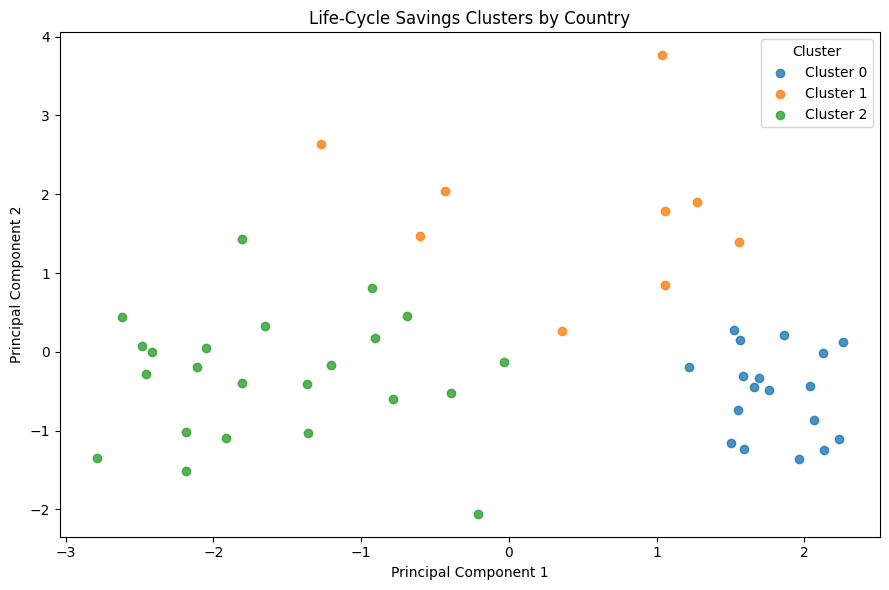

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Select the numeric columns
features = df[["sr", "pop15", "pop75", "dpi", "ddpi"]]

# Standardize the measurements
scaler = StandardScaler()
scaled = scaler.fit_transform(features)

# Group countries into three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(scaled)

# Add the cluster numbers to the results
clustered = features.copy()
clustered["cluster"] = labels

print("Countries per cluster:")
print(clustered["cluster"].value_counts().sort_index())

print("\nAverage measurements by cluster:")
print(clustered.groupby("cluster").mean().round(2))

# Reduce the data to two dimensions for visualization
pca = PCA(n_components=2)
coordinates = pca.fit_transform(scaled)

plt.figure(figsize=(9, 6))

for cluster in sorted(np.unique(labels)):
    mask = labels == cluster
    plt.scatter(
        coordinates[mask, 0],
        coordinates[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.8
    )

plt.title("Life-Cycle Savings Clusters by Country")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
cluster_zero = clustered[clustered["cluster"] == 0]

print("My independently calculated Cluster 0 averages:")
print(cluster_zero.drop(columns="cluster").mean())

print("\nOverall averages:")
print(df.mean(numeric_only=True))

My independently calculated Cluster 0 averages:
sr         6.138889
pop15     44.556111
pop75      1.079444
dpi      337.153333
ddpi       2.359444
dtype: float64

Overall averages:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


So checking Cluster 0 myself, what I found was that average savings ratio was around 6.14, compared to the overall average of 9.67. The values shown matched what the AI-generated code showed, which did confirm that this cluster had a lower average savings ratio than the dataset overall.

So when looking at the three cluster, what I noticed the most was that the countries were split into three groups via their savings and economic status. Out of the three, Cluster 0 had the lowest average savings ratio at around 6.14, while Cluster 1 had the highest at 13.59. One interesting thing also, was that Cluster 2 had a uniquely higher average disposable income than the other groups, sitting at around 1,953.04. This all being said, I sitll wouldn't have complete faith in chatgpt's interpretation of these results as AI can be faulty at times so therefore I would actually go and double check.

Github: https://github.com/leonhong2007/cs82a-portfolio/tree/main/module8